# 150 · A reasoning VLA that drives: NVIDIA Alpamayo 2 Edge, on real roads and in our MuJoCo city
**Alpamayo 2 Edge** (NVIDIA, released Nov 2026) is a driving VLA with **reasoning**: six cameras, the car's last
two seconds of motion and a navigation instruction ("Turn right in 30m") go in; a short **chain-of-causation**
explanation and a **6.4-second trajectory** come out (64 poses at 10 Hz). Under the hood: a 2.45B vision-language
backbone (Cosmos 3 Edge: SigLIP2 vision encoder + a Nemotron language model) and a 0.2B **flow-matching action
expert** that predicts acceleration and curvature, integrated into poses (the head you built in S08 and C8).

This notebook:
1. loads the model and looks inside it;
2. runs it on a real NVIDIA driving clip (PhysicalAI-AV dataset) and changes the instruction (counterfactuals);
3. puts it **in our C8 MuJoCo city**: six simulated cameras, zero-shot. Open loop, then driving closed loop;
4. evaluates it in **shadow mode** (it plans while the expert drives) with NVIDIA's own metric, and checks whether
   its reasoning is **faithful** to what's really there (lecture 150);
5. measures latency, and compares it with the mini driving VLA of capstone C8.

**Setup** (Linux + NVIDIA GPU with ≥ 16 GB and bf16; Colab: an L4 or A100). In a terminal:
```bash
git clone https://github.com/NVlabs/alpamayo2-edge && cd alpamayo2-edge
curl -LsSf https://astral.sh/uv/install.sh | sh
UV_PROJECT_ENVIRONMENT=.venv uv sync --locked --extra notebook
VIRTUAL_ENV=.venv uv pip install mujoco==4.0.0 mujoco-menagerie opencv-python-headless imageio imageio-ffmpeg ipykernel
VIRTUAL_ENV=.venv uv pip install --no-deps -e /path/to/VLA_Udemy
.venv/bin/python -m ipykernel install --user --name alpamayo --display-name "Python (alpamayo)"
.venv/bin/hf download nvidia/Alpamayo2-Edge --revision f8951d095de3589b3face1dec3f4394c8ecedb38 --local-dir ~/alpamayo/model
```
For part 2 (real clips): accept the terms of `nvidia/PhysicalAI-Autonomous-Vehicles` on Hugging Face and run
`.venv/bin/hf auth login`. Without it, part 2 is skipped and everything else still runs.
Licences: code Apache-2.0, weights OpenMDW-1.1, dataset under NVIDIA's own terms.

In [ ]:
import os, time, json, textwrap
os.environ.setdefault("MUJOCO_GL", "egl")
import numpy as np, torch, matplotlib.pyplot as plt, mujoco
from alpamayo2_edge.checkpoint import load_model
from vlacourse.city import DriveEnv, REASON_TEXT
from vlacourse.alpamayo_city import (AlpamayoInputs, AlpamayoDriver, run_alpamayo, nav_text, CAM_IDS, CAM_LABEL, SETTINGS)
from vlacourse.drive_policy import run_episode, SCENARIOS
from vlacourse.drive_film import Film, preview
from vlacourse import showcase as sc
from vlacourse.viz import show_video, show_images

MODEL = os.path.expanduser(os.environ.get("ALPAMAYO_MODEL", "~/alpamayo/model"))
os.makedirs("outputs", exist_ok=True); os.makedirs("results", exist_ok=True)
print(torch.__version__, torch.cuda.get_device_name(0), "bf16:", torch.cuda.is_bf16_supported())

## 1. The model

In [2]:
t0 = time.time()
model, _ = load_model(MODEL, device="cuda")
print(f"loaded in {time.time() - t0:.0f}s: {sum(p.numel() for p in model.parameters()) / 1e9:.2f}B parameters, {next(model.parameters()).dtype}")
def count(m):
    return sum(p.numel() for p in m.parameters())
for name, child in model.named_children():
    n = count(child)
    if n > 1e6:
        print(f"  {name:28s} {n / 1e6:8.1f}M")
        for sub, g in child.named_children():
            if count(g) > 5e7:
                print(f"     {sub:25s} {count(g) / 1e6:8.1f}M")

Loading weights:   0%|          | 0/907 [00:00<?, ?it/s]

loaded in 3s: 2.65B parameters, torch.bfloat16
  vlm                            2452.4M
     model                       2175.6M
     lm_head                      276.8M
  expert                          198.8M
     expert                       198.2M


## 2. A real drive (NVIDIA PhysicalAI-AV)
NVIDIA's example: clip `ea7bbd31…` at t = 4.0 s, instruction "Turn right in 30m". The loader reads 22 images
(front-wide and front-tele at −2, −1, −0.5, −0.1, 0 s; the four others at −1, −0.1, 0 s) and 20 past poses.
We run 6 candidates, then **change only the instruction** and see if the trajectories follow.

In [3]:
real = None
try:
    from alpamayo2_edge.load_physical_aiavdataset import load_physical_aiavdataset
    import physical_ai_av
    avdi = physical_ai_av.PhysicalAIAVDatasetInterface()
    CLIP, T0 = "ea7bbd31-b7a5-4972-8dbd-7089e6b53de4", 4_000_000
    real = {nav: load_physical_aiavdataset(CLIP, t0_us=T0, nav_text=nav, avdi=avdi)
            for nav in ("Turn right in 30m", "Turn left in 30m", "Continue straight")}
except Exception as ex:                     # no dataset access: skip this part
    print("Part 2 skipped (PhysicalAI-AV not accessible):", type(ex).__name__, str(ex)[:200])

if real is not None:
    d0 = real["Turn right in 30m"]
    cams = d0["camera_indices"].tolist()
    last = {c: i for i, c in enumerate(cams)}                      # the t0 frame of each camera
    show_images([d0["image_frames"][last[c], 0].permute(1, 2, 0).numpy() for c in CAM_IDS], [CAM_LABEL[c] for c in CAM_IDS], cols=3)
    real_out = {}
    for nav, d in real.items():
        traj, cot, sec = run_alpamayo(model, d)
        real_out[nav] = (traj, cot, sec)
        print(f"\n“{nav}”  ({sec:.2f} s)")
        for k, c in enumerate(cot):
            print(f"  [{k + 1}] {c}")
    fig, ax = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
    hist = d0["ego_history_xyz"][0].numpy()
    for a, (nav, (traj, cot, sec)) in zip(ax, real_out.items()):
        a.plot(hist[:, 1], hist[:, 0], "k-.", lw=2, label="past 2 s")
        for t in traj:
            a.plot(t[:, 1], t[:, 0], lw=2)
        a.invert_xaxis(); a.set_aspect("equal"); a.set_title(f"“{nav}”"); a.set_xlabel("left (m)")
    ax[0].set_ylabel("forward (m)"); ax[0].legend(); plt.suptitle("same scene, three instructions: 6 candidates each"); plt.show()

Part 2 skipped (PhysicalAI-AV not accessible): GatedRepoError 401 Client Error. (Request ID: Root=1-6af9de95-163356931489537b383f75da;a0cc29a6-43cb-4f2d-a181-e65002c5953b)

Cannot access gated repo for url https://huggingface.co/api/datasets/nvidia/PhysicalAI-Au


## 3. Alpamayo in our MuJoCo city (zero-shot)
Our C8 ego car gets Alpamayo's camera rig: cross-left / cross-right (120°), front-wide (120°), rear-left /
rear-right (70°), front-tele (30°), as pinhole cameras. We keep a 2-second buffer of all six, the last 20 poses,
and turn our route into Alpamayo's instruction format. **Nothing is retrained**: it has never seen a rendering.

[transformers] Calling `crop` with a positive value is deprecated and will be removed in version 5.18. Please use a negative integer to remove that number of tokens from the cache instead.



green light, left turn ahead  ·  instruction “Turn left in 20m”  ·  true light: G  ·  speed 30 km/h  ·  1.87 s
  [1] Proceed forward and turn left at the intersection to follow our route, as the traffic signal is green and our path is clear.   → after 3 s: 22.2 m ahead, +0.1 m left
  [2] Proceed forward and turn left through the intersection to follow our route, as the traffic signal displays a green left-turn arrow.   → after 3 s: 22.0 m ahead, +1.5 m left
  [3] <NOMINAL>   → after 3 s: 23.0 m ahead, +0.4 m left
  [4] Proceed into the intersection and turn left to follow our route, as the traffic signal has turned green.   → after 3 s: 23.6 m ahead, +0.8 m left
  [5] Proceed forward and turn left at the intersection to follow our route, as the traffic light is green.   → after 3 s: 23.0 m ahead, +0.4 m left
  [6] <NOMINAL>   → after 3 s: 23.2 m ahead, +0.2 m left



the light turns red  ·  instruction “Continue straight”  ·  true light: Y  ·  speed 32 km/h  ·  1.38 s
  [1] Proceed straight through the intersection to follow our route, as the traffic light has turned yellow and we cannot stop safely before the stop line.   → after 3 s: 25.9 m ahead, -0.1 m left
  [2] Proceed straight through the intersection to follow our route, as the traffic light has turned yellow and we cannot stop safely before the stop line.   → after 3 s: 25.6 m ahead, +0.2 m left
  [3] <NOMINAL>   → after 3 s: 25.8 m ahead, -0.0 m left
  [4] Proceed straight through the intersection to follow our route, as the traffic light has turned yellow.   → after 3 s: 26.4 m ahead, -0.1 m left
  [5] Proceed straight through the intersection to follow our route, as the traffic light has turned yellow.   → after 3 s: 26.0 m ahead, -0.1 m left
  [6] Proceed straight through the intersection to follow our route, as the traffic light has turned yellow and we cannot stop safely before the 


a pedestrian steps out  ·  instruction “Continue straight”  ·  true light: R  ·  speed 7 km/h  ·  1.58 s
  [1] Continue decelerating to stop before the crosswalk for the red traffic light and the pedestrian crossing our path.   → after 3 s: 2.5 m ahead, +0.0 m left
  [2] Decelerate to a stop before the intersection for the red traffic light and the pedestrian crossing our lane.   → after 3 s: 1.7 m ahead, +0.0 m left
  [3] Continue decelerating to a stop before the intersection to continue straight along our route, as the pedestrian has cleared our path but the traffic light ahead is red.   → after 3 s: 1.1 m ahead, -0.0 m left
  [4] Continue decelerating to stop at the stop line for the red traffic light and the pedestrian crossing our lane.   → after 3 s: 3.1 m ahead, -0.0 m left
  [5] Stop and wait at the stop line for the red traffic light to follow our route straight through the intersection.   → after 3 s: 1.4 m ahead, -0.0 m left
  [6] Brake to a stop before the crosswalk as th

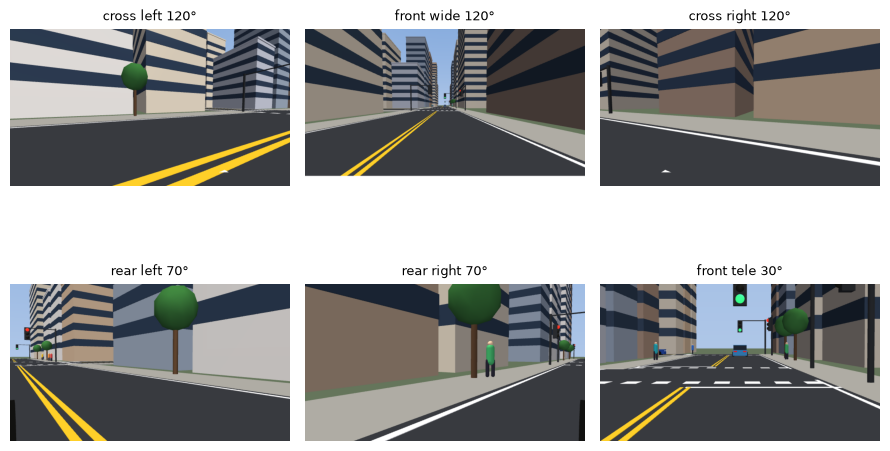

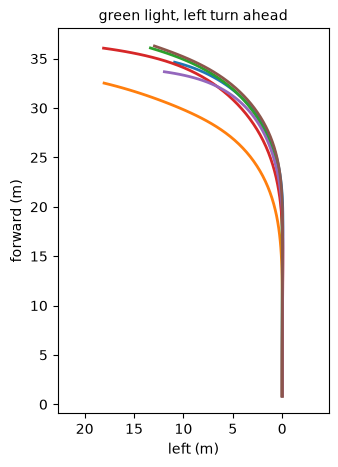

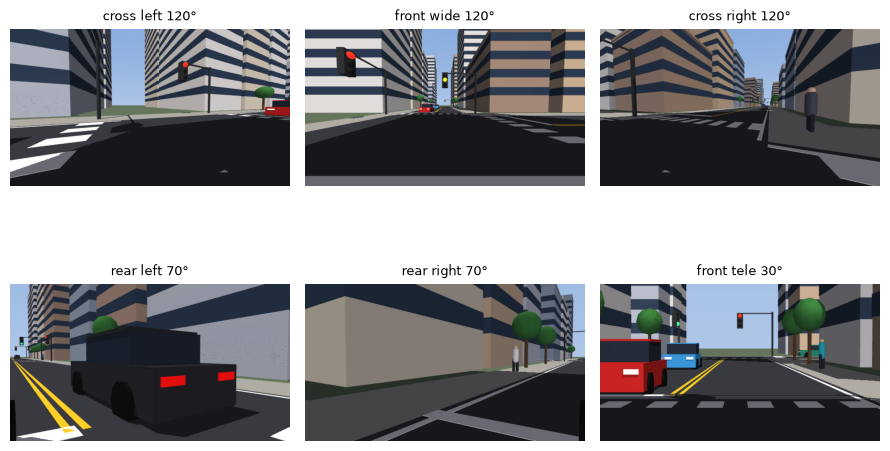

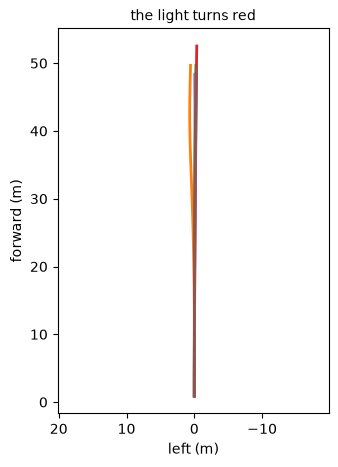

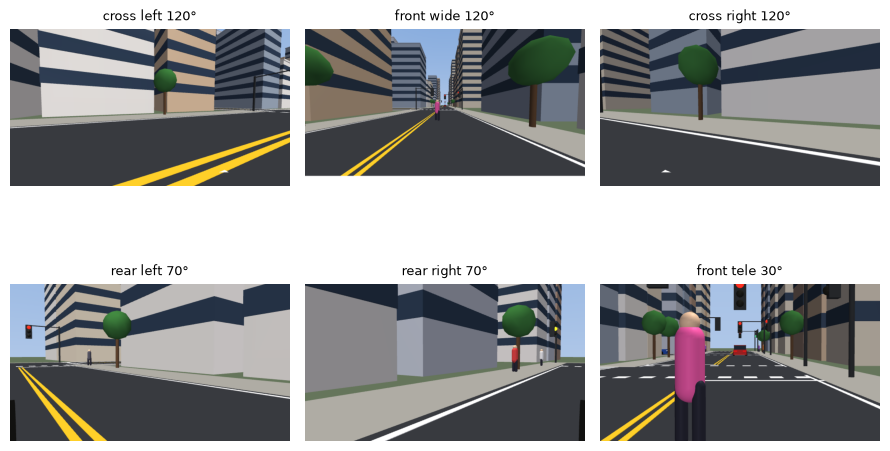

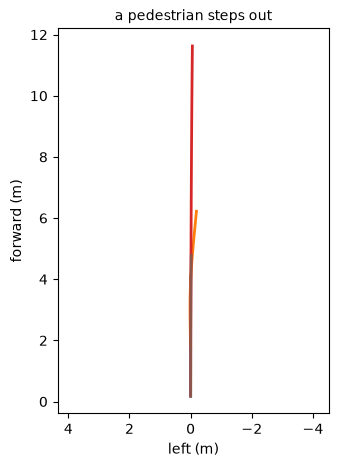

In [4]:
env = DriveEnv(av_rig=True)
inp = AlpamayoInputs(env)
def situation(seed, scenario, seconds):
    env.reset(seed=seed, scenario=scenario); inp.reset()
    for _ in range(int(seconds / 0.1)):
        a, _ = env.expert(); env.step(a); inp.record()
    return inp.sample(nav_text(env))

cases = {"green light, left turn ahead": (900003, "left", 3.0), "the light turns red": (901001, "red", 4.0),
         "a pedestrian steps out": (902002, "jaywalker", 3.4)}
city = {}
for name, (seed, scen, sec) in cases.items():
    d = situation(seed, scen, sec)
    traj, cot, s = run_alpamayo(model, d)
    J = env.route.next_junction(env.ego["s"])
    light = env.lights.state(J["node"], J["d_in"], env.t) if J else None
    city[name] = dict(images={c: inp.buf[-1][1][c] for c in CAM_IDS}, traj=traj, cot=cot, nav=d["nav_text"][0], light=light,
                      speed=env.ego["v"], seconds=s)
    print(f"\n{name}  ·  instruction “{d['nav_text'][0]}”  ·  true light: {light}  ·  speed {env.ego['v'] * 3.6:.0f} km/h  ·  {s:.2f} s")
    for k, c in enumerate(cot):
        print(f"  [{k + 1}] {c}   → after 3 s: {traj[k, 29, 0]:.1f} m ahead, {traj[k, 29, 1]:+.1f} m left")
for name, c in city.items():
    show_images([c["images"][k] for k in CAM_IDS], [CAM_LABEL[k] for k in CAM_IDS], cols=3)
    plt.figure(figsize=(3.5, 5))
    for t in c["traj"]:
        plt.plot(t[:, 1], t[:, 0], lw=2)
    plt.gca().invert_xaxis(); plt.axis("equal"); plt.title(name, fontsize=10); plt.xlabel("left (m)"); plt.ylabel("forward (m)"); plt.show()

### Counterfactual instructions in the city
Same scene (approaching an intersection), three instructions. A model that *uses* the instruction must change
its trajectories; one that ignores it won't.

“Turn left in 20m”: Proceed into the intersection and turn left to follow our route, as permitted by the green traffic light.


“Turn right in 20m”: Proceed forward through the crosswalk as the traffic light has turned green.


“Continue straight”: Proceed straight through the intersection to follow our route, as permitted by the green traffic light.


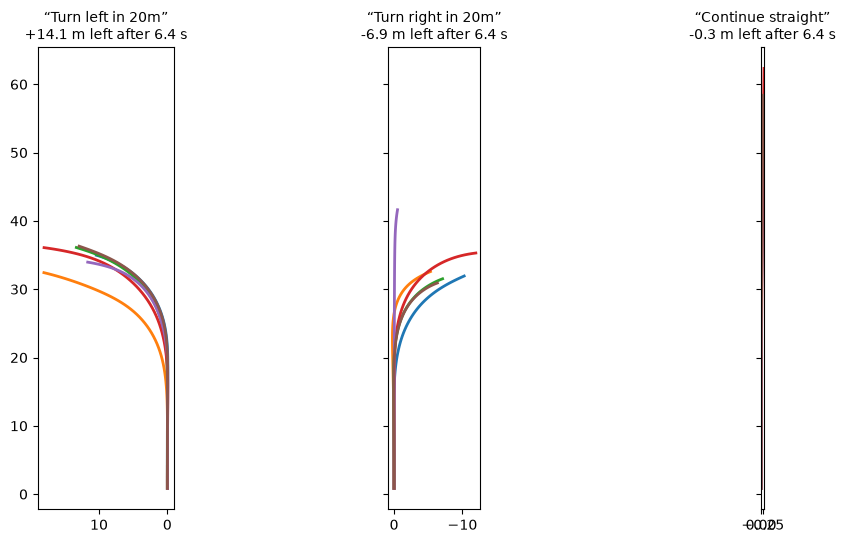

In [5]:
d = situation(900003, "left", 3.0)
fig, ax = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
for a, nav in zip(ax, ["Turn left in 20m", "Turn right in 20m", "Continue straight"]):
    d["nav_text"] = [nav]
    traj, cot, s = run_alpamayo(model, d)
    for t in traj:
        a.plot(t[:, 1], t[:, 0], lw=2)
    a.invert_xaxis(); a.set_aspect("equal"); a.set_title(f"“{nav}”\n{np.mean(traj[:, -1, 1]):+.1f} m left after 6.4 s", fontsize=10)
    print(f"“{nav}”: {next((c for c in cot if c != '<NOMINAL>'), '<NOMINAL>')}")
plt.show()

### Ask it about the scene (free-form question answering)
The same model also answers questions about its six cameras (4 frames each).

In [6]:
from alpamayo2_edge.helper import prepare_vqa_inputs, to_device
from alpamayo2_edge.sample import VQA_CAMERA_PIXEL_BOUNDS
from alpamayo2_edge.text_tasks import generate_vqa_answer
def vqa_sample():
    frames, cams, stamps = [], [], []
    t0 = inp.buf[-1][0]
    for c in CAM_IDS:
        for o in (-0.3, -0.2, -0.1, 0.0):
            t, imgs, _ = inp._at(t0 + o)
            frames.append(imgs[c]); cams.append(c); stamps.append(int(round(t * 1e6)))
    return {"image_frames": torch.from_numpy(np.stack(frames)).permute(0, 3, 1, 2).unsqueeze(1).contiguous(),
            "camera_indices": torch.tensor(cams), "absolute_timestamps": torch.tensor(stamps, dtype=torch.int64),
            "camera_pixel_bounds": dict(VQA_CAMERA_PIXEL_BOUNDS), "min_pixels": 163840, "max_pixels": 196608,
            "input_profile": "vqa_6cam_4f", "clip_id": "mujoco-city", "t0_us": int(round(t0 * 1e6)), "provenance": {}}
situation(902002, "jaywalker", 3.4)
Q = "How should the ego vehicle drive in this scene? Describe the relevant road users, traffic signals, and hazards."
vin = to_device(prepare_vqa_inputs(vqa_sample(), model.config, model.tokenizer, question=Q), device="cuda")
with torch.autocast("cuda", dtype=torch.bfloat16):
    answer = generate_vqa_answer(model, vin, max_new_tokens=400)
print("Q:", Q, "\n\nA:", textwrap.fill(answer, 110))

Q: How should the ego vehicle drive in this scene? Describe the relevant road users, traffic signals, and hazards. 

A: Stop and wait behind the pedestrian in the crosswalk, as the traffic light ahead is red and the pedestrian is
crossing our path.


## 4. Closed loop: Alpamayo drives in the city
Every second (10 control steps) we ask for 6 candidates and follow candidate 1: pure pursuit for steering, the
trajectory's own speed profile for acceleration. The simulation **waits while the model thinks**, so this measures
driving, not real-time performance. One episode per scenario type, same seeds as C8.

In [7]:
from vlacourse.alpamayo_city import shadow_metrics
from vlacourse.drive_policy import ExpertDriver
from vlacourse.city import PITCH, RW, N
drv = AlpamayoDriver(model, inp)
closed, diag = [], None
for i, scen in enumerate(SCENARIOS):
    seed = 900_000 + 1000 * i
    path = []
    def track(e, p):
        path.append(e.ego["xy"].copy())
    info = run_episode(env, drv, seed, scen, on_step=track)
    outcome = "arrived" if info["success"] else (f"collision ({info['collision']})" if info["collision"] else
                                                 "left the road" if info["offroad"] else "wrong way" if info["offroute"] else "timeout")
    closed.append(dict(scenario=scen, seed=seed, outcome=outcome, red_light=int(info["red_light"]), t=float(info["t"])))
    print(f"{scen:10s} {outcome:24s} after {info['t']:4.1f} s, red lights run: {info['red_light']}")
    if scen == "left":
        diag = (np.array(path), [L["world"] for L in drv.log], env.route.p.copy())

random     left the road            after 17.0 s, red lights run: 1


red        collision (car)          after  7.6 s, red lights run: 0


jaywalker  collision (pedestrian)   after 16.3 s, red lights run: 0


left       left the road            after 10.2 s, red lights run: 1


right      collision (car)          after  7.5 s, red lights run: 1


What went wrong in the left turn? Everything from above: road (grey), our route's lane centre (blue), every plan
(green = candidate 1, which the car followed), and the path driven (red).

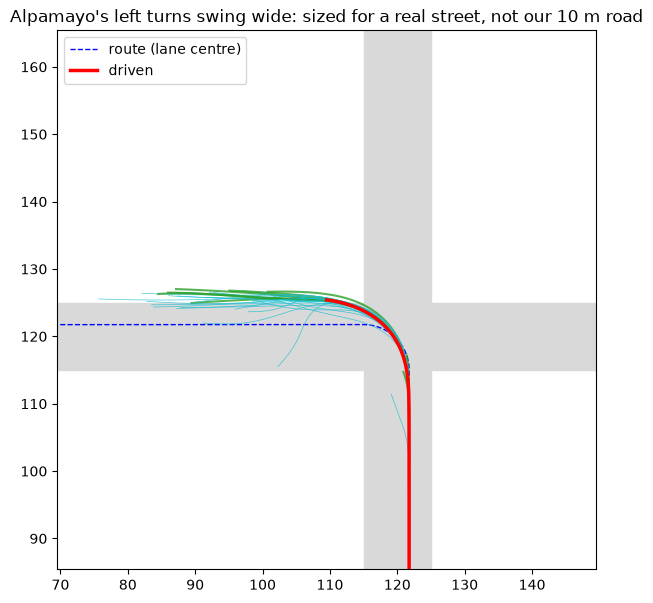

In [8]:
if diag is not None:
    path, plans, route = diag
    fig, ax = plt.subplots(figsize=(7, 7))
    for k in range(N):
        ax.axhspan(k * PITCH - RW, k * PITCH + RW, color="0.85"); ax.axvspan(k * PITCH - RW, k * PITCH + RW, color="0.85")
    ax.plot(route[:, 0], route[:, 1], "b--", lw=1, label="route (lane centre)")
    for ws in plans:
        for j, w in enumerate(ws):
            ax.plot(w[:, 0], w[:, 1], c="tab:green" if j == 0 else "tab:cyan", lw=1.5 if j == 0 else 0.5, alpha=0.8)
    ax.plot(path[:, 0], path[:, 1], "r-", lw=2.5, label="driven")
    c = path[-1]; ax.set_xlim(c[0] - 40, c[0] + 40); ax.set_ylim(c[1] - 40, c[1] + 40); ax.set_aspect("equal"); ax.legend()
    ax.set_title("Alpamayo's left turns swing wide: sized for a real street, not our 10 m road"); plt.show()

The car follows Alpamayo's trajectory faithfully (red on green): the controller isn't the problem. Alpamayo
understands the scene (it turns left, on green), but its **metric geometry** is off here: its turns are sized for
real streets, seen through real (fisheye) cameras, and our pinhole renders of a narrow road break that calibration.
Sim-to-real in reverse.

## 5. Shadow mode: the expert drives, Alpamayo plans alongside
How do you evaluate a driving model you don't trust to drive? Car makers run new models in **shadow mode**: the
model sees everything and plans, but doesn't control the car; afterwards every plan is compared with what the car
really did. Here the expert drives, and we score each of Alpamayo's plans over the next 3 s:
**minADE₆** (average distance of the best of 6 candidates: NVIDIA's open-loop metric, 0.52 m at 5 s on real data),
the ADE of candidate 1, and whether candidate 1 and the car agree on **stop vs go**.

In [9]:
shadow = AlpamayoDriver(model, inp, shadow=ExpertDriver())
N_PER = int(os.environ.get("ALPAMAYO_EPISODES", 3))
scores, faith, lat = [], [], []
t0 = time.time()
for i, scen in enumerate(SCENARIOS):
    for k in range(N_PER):
        run_episode(env, shadow, 900_000 + 1000 * i + k, scen)
        sm = shadow_metrics(shadow.log, shadow.track)
        scores += [dict(m, scenario=scen) for m in sm]
        faith += [dict(light=L["light"], cot=L["cot"][0]) for L in shadow.log]
        lat += [L["seconds"] for L in shadow.log]
    s_ = [m for m in scores if m["scenario"] == scen]
    print(f"{scen:10s} {len(s_):3d} plans  minADE6@3s {np.mean([m['minade'] for m in s_]):5.2f} m   candidate-1 ADE "
          f"{np.mean([m['ade1'] for m in s_]):5.2f} m   stop/go agreement {np.mean([m['stop_go_agree'] for m in s_]):4.0%}"
          f"   ({time.time() - t0:.0f}s)")
print(f"all: {len(scores)} plans, minADE6@3s {np.mean([m['minade'] for m in scores]):.2f} m, "
      f"stop/go agreement {np.mean([m['stop_go_agree'] for m in scores]):.0%}")
json.dump(dict(closed_loop=closed, shadow=scores, latency=lat), open("results/150_alpamayo_city.json", "w"))

random      83 plans  minADE6@3s  0.36 m   candidate-1 ADE  0.64 m   stop/go agreement  92%   (303s)


red         82 plans  minADE6@3s  0.33 m   candidate-1 ADE  0.57 m   stop/go agreement  89%   (460s)


jaywalker  133 plans  minADE6@3s  0.37 m   candidate-1 ADE  0.60 m   stop/go agreement  84%   (679s)


left       131 plans  minADE6@3s  0.31 m   candidate-1 ADE  0.55 m   stop/go agreement  92%   (895s)


right       80 plans  minADE6@3s  0.43 m   candidate-1 ADE  0.65 m   stop/go agreement  90%   (1032s)
all: 509 plans, minADE6@3s 0.35 m, stop/go agreement 89%


### Is the reasoning faithful?
When candidate 1's reasoning names the traffic light's colour, is that the light's true colour (our approach's
light, within 45 m)?

In [10]:
said = {"green": [], "red": [], "yellow": []}
for f in faith:
    c = f["cot"].lower()
    for colour in said:
        if colour in c and f["light"] is not None:
            said[colour].append({"G": "green", "R": "red", "Y": "yellow"}[f["light"]] == colour)
print(f"{len(faith)} plans; {sum(f['cot'] != '<NOMINAL>' for f in faith)} with reasoning text, "
      f"{sum(any(w in f['cot'].lower() for w in ('light', 'signal')) for f in faith)} mention a light or signal")
for colour, ok in said.items():
    if ok:
        print(f"  says '{colour}': matches the true light {np.mean(ok):.0%} of {len(ok)} times")

554 plans; 520 with reasoning text, 434 mention a light or signal
  says 'green': matches the true light 63% of 209 times
  says 'red': matches the true light 76% of 249 times
  says 'yellow': matches the true light 32% of 40 times


## 6. Latency, and the mini VLA of C8 next to it

In [11]:
print(f"Alpamayo call (6 candidates with reasoning, 10 flow steps): median {np.median(lat):.2f} s, p90 "
      f"{np.percentile(lat, 90):.2f} s on {torch.cuda.get_device_name(0)} (PyTorch SDPA, no CUDA graphs)")
c8 = "../S17_Capstones/results/C8_closed_loop.json"
if os.path.exists(c8):
    m = json.load(open(c8))["model"]
    print(f"C8 mini VLA, trained in this city, closed loop: {np.mean([r['success'] for r in m]):.0%} of {len(m)} routes completed")
print("""
                     Alpamayo 2 Edge                         C8 mini driving VLA
parameters           ~2.65B                                   ~15M
cameras              6 (22 frames over 2 s)                   1 (2 frames)
instruction          "Turn left in 30m"                       "turn left at the next intersection"
output               6.4 s trajectory + reasoning text        2 s plan (a, κ) + 1 of 6 reasons
action head          flow matching on (a, κ)                  flow matching on (a, κ)
training data        ~115,000 h of real driving               ~2 h of simulated expert driving
in our city          reads the scene, turns too wide          trained here: drives it, but only here
""")

Alpamayo call (6 candidates with reasoning, 10 flow steps): median 1.48 s, p90 2.03 s on NVIDIA RTX PRO 6000 Blackwell Workstation Edition (PyTorch SDPA, no CUDA graphs)
C8 mini VLA, trained in this city, closed loop: 90% of 150 routes completed

                     Alpamayo 2 Edge                         C8 mini driving VLA
parameters           ~2.65B                                   ~15M
cameras              6 (22 frames over 2 s)                   1 (2 frames)
instruction          "Turn left in 30m"                       "turn left at the next intersection"
output               6.4 s trajectory + reasoning text        2 s plan (a, κ) + 1 of 6 reasons
action head          flow matching on (a, κ)                  flow matching on (a, κ)
training data        ~115,000 h of real driving               ~2 h of simulated expert driving
in our city          reads the scene, turns too wide          trained here: drives it, but only here



## 7. Share-ready video: Alpamayo in shadow mode
The expert drives; Alpamayo's six candidate trajectories are drawn on the road with its reasoning, live.

In [12]:
film = Film(env, shadow)
video = sc.title_card("NVIDIA Alpamayo 2 Edge in a MuJoCo city", "zero-shot, in shadow mode: 6 simulated cameras + “Turn left in 30m”\n"
                      "→ 6 trajectories + why · the expert drives", size=(1080, 1920), n=75)
for scen, title in [("left", "Left turn at a green light"), ("red", "The light turns red"), ("jaywalker", "A pedestrian steps out")]:
    frames, info = film.episode(900_000 + 1000 * SCENARIOS.index(scen), scen, label=title, title=f"Alpamayo 2 Edge (shadow mode) · {title}")
    video += sc.title_card(title, "NVIDIA Alpamayo 2 Edge, zero-shot, shadow mode", size=(1080, 1920), n=40) + frames
show_video(preview(video), fps=15, title="150 alpamayo in mujoco preview", width=960)
sc.export(video, "outputs/150_alpamayo_in_mujoco.mp4", fps=30)

saved outputs/150_alpamayo_in_mujoco.mp4  (112.9 MB)


['outputs/150_alpamayo_in_mujoco.mp4']

## Takeaways
- A reasoning VLA trained on real driving **reads** a stylized simulator zero-shot: traffic lights, pedestrians,
  crossing cars, the instruction. Its **metric geometry** doesn't transfer: turns sized for real streets and real
  lenses leave our narrow road. Cameras and scale are part of the model's input distribution.
- **Shadow mode** evaluates a model you don't trust to drive: plan alongside, score against reality.
- Reasoning is an **interface**, not a guarantee: we checked its light colours against the truth.
- **Latency** is the price of reasoning: seconds per call here; real cars replan at ~10 Hz, which is why NVIDIA
  ships CUDA-graph / FlashAttention paths and DRIVE Thor deployment.
- The C8 mini VLA uses the same action representation at ~1/180th of the size: the architecture scales; the data
  (and its match to the deployment world) is what you can't shrink.

## Exercises
1. **Fix the geometry:** widen the city's roads (`RW` in `vlacourse/city.py`). Does Alpamayo's left turn stay on the road?
2. **Fisheye:** render the 120° cameras with an f-theta lens (render a wider pinhole image, remap with OpenCV).
   Does minADE improve?
3. Replan every 0.5 s instead of 1 s in closed loop. Better? What latency budget would that need in a real car?
4. Follow the **median** candidate instead of candidate 1 (S11 114: choosing among samples).
5. Give it a wrong instruction ("Turn left" where there is no road to the left). What does it say and do?